# ICT-36d — Pont F-Lens x Higuchi, jambe 2 : la decorrelation temporelle

ICT-36c a etabli la reponse calibree de quatre instruments de dimensionnalite au **nombre de facteurs partages** k : tous decroissent ensemble. Restait le trou du pont vers Subramani et al. 2026 (LSD/MEG) : sous LSD, la HFD **monte**, et ICT-36c notait qu'une HFD qui monte est coherente avec une **decorrelation temporelle**, pas avec l'ajout de facteurs partages — une note d'honnetete, pas une mesure.

Ce notebook mesure ce qui manquait : a geometrie spatiale **constante** (k = 3 facteurs, loadings orthonormaux, covariance unitaire a la stationnarite — identique pour tous les terrains), on fait varier uniquement la **persistance temporelle** rho des facteurs AR(1), de +0.9 (canaux lisses, fortement autocorreles) a -0.9 (oscillation rapide, anticorrelation pas-a-pas). C'est la manipulation qui isole ce que LSD change dans le signal cortical sans changer la carte des facteurs.

**Navigation** : [Index ICT-Series](README.md) | [<< ICT-36c](ICT-36c-FLens-HiguchiBridge-Python.ipynb) | [>> ICT-37](ICT-37-FLens-BeliefState-Python.ipynb)

**Question pre-enregistree** : lesquels des quatre instruments repondent a rho, et en quel sens ? La prediction de conception (inscrite avant la mesure, tranchee en section 5) : les instruments temporels HFD et LZC montent quand rho decroît ; les instruments spatiaux NC@95 et PR — qui lisent le spectre de covariance des canaux, invariant en esperance sous rho — ne se separent pas.

Grain #20463, tranche 2 (terrain synthetique) : la jambe MEG reelle reste conditionnee a l'acces aux donnees (verdict etabli dans le grain : non publiques, acces sur demande).

## 1. Mise en place

Imports et racine canonique de la serie (idiome ICT-36) : on remonte les parents depuis le dossier courant jusqu'au package `ict/`. L'organe `flens_traces` et la geometrie factorisee sont importes tels quels — jamais reimplementes ici.

In [1]:
import sys
from pathlib import Path

import numpy as np
import antropy as ent
import matplotlib.pyplot as plt

ICT_ROOT = Path.cwd()
while not (ICT_ROOT / "ict" / "__init__.py").exists() and ICT_ROOT != ICT_ROOT.parent:
    ICT_ROOT = ICT_ROOT.parent
assert (ICT_ROOT / "ict" / "__init__.py").exists(), (
    f"package ict/ introuvable en remontant depuis {Path.cwd().name}")
if str(ICT_ROOT) not in sys.path:
    sys.path.insert(0, str(ICT_ROOT))

from ict.flens_traces import measure_flens
from ict.factor_geometry import weighted_pca

print("organe flens_traces resolu depuis le dossier", ICT_ROOT.name)
print("antropy importe : higuchi_fd, lziv_complexity disponibles")

# Instruments : identiques a ICT-36c.
K_MAX_HFD = 18          # Kmax du papier Subramani et al. 2026
T_TOKENS = 2048         # longueur temporelle par "prompt"
D_MODEL = 64            # nombre de canaux
SIG_FACTOR = 1.0        # amplitude par facteur
SIG_NOISE = 0.32        # bruit de canal (~10 dB par facteur)
SEEDS = [0, 1, 7, 42]   # multi-seed (>= 4, discipline maison)
N_PROMPTS = 3           # prompts par jeu (2 jeux -> 6 prompts par terrain)

# La manipulation de ce notebook : rho varie, k reste fixe.
K_FIXE = 3
RHO_GRID = [0.9, 0.5, 0.0, -0.5, -0.9]

organe flens_traces resolu depuis le dossier ICT-Series
antropy importe : higuchi_fd, lziv_complexity disponibles


## 2. Terrain GHMM — copie pedagogique declaree de ICT-36c, rho parametre

Le generateur vit dans le notebook ICT-36c (il n'est pas exporte au module `ict/`) : cette cellule le recopie **a l'identique pres du parametre** — `build_terrain` prend maintenant `rho` en argument au lieu de la constante de module. Copie pedagogique declaree, motif : la jambe 2 manipule la persistance temporelle, la jambe 1 manipulait k ; tout le reste (normalisation AR(1) stationnaire, loadings QR orthonormaux, contrat `dense` de l'organe, jeux A/B a loadings distincts) est preserve ligne a ligne.

Point decisif pour la question posee : a la stationnarite, la covariance des facteurs normalises vaut l'identite **quel que soit rho** — le melange `loadings @ factors` a donc la meme covariance spatiale sur toute la grille. Seule la structure temporelle change.

In [2]:
def make_factors(n_steps, k_active, rng, rho):
    """k processus AR(1) stationnaires, normalises a un ecart-type unitaire."""
    eps = rng.standard_normal((n_steps, k_active))
    factors = np.empty_like(eps)
    factors[0] = eps[0]
    for t in range(1, n_steps):
        factors[t] = rho * factors[t - 1] + np.sqrt(1.0 - rho ** 2) * eps[t]
    return factors


def make_loadings(d_model, k_active, rng):
    """Matrice de loadings (d_model, k) a colonnes orthonormales (QR)."""
    q, _ = np.linalg.qr(rng.standard_normal((d_model, k_active)))
    return q


def build_terrain(k_active, seed, rho, n_prompts=N_PROMPTS, t_tokens=T_TOKENS,
                  d_model=D_MODEL, sig_factor=SIG_FACTOR, sig_noise=SIG_NOISE):
    """Terrain GHMM a k facteurs de persistance rho -> capture dense (contrat flens_traces).

    Jeux A et B : memes facteurs actifs, loadings differents — l'alignement
    intra-jeu doit depasser la nulle appariee, l'inter-jeu rester proche.
    """
    rng = np.random.default_rng(seed)
    loadings = {
        s: make_loadings(d_model, max(k_active, 1),
                         np.random.default_rng(seed * 100 + i))
        for i, s in enumerate("AB")
    }
    prompts = {}
    for i_set, s in enumerate("AB"):
        for i in range(n_prompts):
            factors = make_factors(t_tokens, max(k_active, 1), rng, rho)
            noise = sig_noise * rng.standard_normal((t_tokens, d_model))
            if k_active == 0:
                resid = noise
            else:
                signal = sig_factor * (loadings[s] @ factors.T).T
                resid = signal + noise
            prompts[(s, i)] = {
                "tokens": np.array([f"tok{j}" for j in range(t_tokens)]),
                "resid": resid.astype(np.float32),
            }
    meta = {"model": "ghmm-synth", "layer": 0, "seed": seed,
            "variant": f"k{k_active}_rho{rho}", "d_model": d_model}
    return {"meta": meta, "prompts": prompts}


terrain_frais = build_terrain(K_FIXE, seed=0, rho=0.9)
resid_frais = terrain_frais["prompts"][("A", 0)]["resid"]
terrain_alt = build_terrain(K_FIXE, seed=0, rho=-0.9)
resid_alt = terrain_alt["prompts"][("A", 0)]["resid"]
print("terrain k=3, rho=+0.9 :", resid_frais.shape[0], "pas x", resid_frais.shape[1], "canaux (float32)")
print("covariance spatiale (trace normalisee) :",
      round(float(np.trace(np.cov(resid_frais.T))) / D_MODEL, 3), "(rho=+0.9)",
      round(float(np.trace(np.cov(resid_alt.T))) / D_MODEL, 3), "(rho=-0.9)")

terrain k=3, rho=+0.9 : 2048 pas x 64 canaux (float32)
covariance spatiale (trace normalisee) : 0.149 (rho=+0.9) 0.151 (rho=-0.9)


## 3. Premiers temoins : les instruments temporels voient deja rho

Avant le balayage, deux terrains au meme seed ne different que par rho. La HFD par canal (moyenne sur les 64 canaux) et la LZC binarisee au signe sont calculees comme en ICT-36c — `antropy.higuchi_fd` avec kmax = 18, exactement le choix du papier.

In [3]:
def channel_hfd(resid):
    """HFD moyenne par canal (kmax = 18, comme le papier)."""
    return float(np.mean([
        ent.higuchi_fd(resid[:, j].astype(np.float64), kmax=K_MAX_HFD)
        for j in range(resid.shape[1])
    ]))


def channel_lzc(resid):
    """LZC normalisee moyenne par canal, binarisation par le signe."""
    return float(np.mean([
        ent.lziv_complexity((resid[:, j] > 0).astype(np.uint8).tolist(),
                            normalize=True)
        for j in range(resid.shape[1])
    ]))


print("Temoins k=3, seed 0, jeu A, prompt 0 :")
print(f"{'rho':>6} {'HFD':>8} {'LZC':>8}")
for rho in (0.9, 0.0, -0.9):
    resid = build_terrain(K_FIXE, seed=0, rho=rho)["prompts"][("A", 0)]["resid"]
    print(f"{rho:>6} {channel_hfd(resid):8.4f} {channel_lzc(resid):8.4f}")

Temoins k=3, seed 0, jeu A, prompt 0 :
   rho      HFD      LZC


   0.9   1.9499   0.9936


   0.0   2.0004   1.0474


  -0.9   2.0088   0.9912


### Lecture du resultat

A un seul prompt, les deux instruments temporels **montent de rho=+0.9 a rho=0.0** : un facteur AR(1) a rho nul est un bruit, le canal melange des composantes moins lisibles, la trajectoire est moins reguliere et sa dimension fractale remonte vers celle d'un bruit blanc. Mais a rho=-0.9, les deux se separent : la HFD continue de monter (2,0088), la LZC **redescend** sous son niveau de depart (0,9912). Premier indice d'une divergence qui structurera le verdict : une oscillation pas-a-pas tres negative est quasi periodique — reguliere au sens fractal (HFD haute) mais *previsible* une fois binarisee au signe (LZC basse). Un temoin n'est pas une mesure : il faut le balayage multi-seed pour trancher, et surtout verifier la contre-prediction — que les instruments **spatiaux** ne bougent pas.

## 4. Balayage rho x seeds — la question pre-enregistree, tranchee par la mesure

Quatre instruments par terrain : NC@95 par l'organe `measure_flens` (concentration du spectre de covariance par prompt), PR sur le spectre PCA pondere de l'organe (participation ratio, Shai et al. 2024), HFD et LZC par canal. Cinq valeurs de rho, quatre seeds, k = 3 fixe partout.

In [4]:
def effective_pr(resid):
    """Participation ratio sur le spectre PCA pondere de l'organe (Shai et al. 2024)."""
    _, _, _, evr = weighted_pca(resid.astype(np.float64))
    return float(1.0 / np.sum(evr ** 2))


rows = []
for rho in RHO_GRID:
    for seed in SEEDS:
        terrain = build_terrain(K_FIXE, seed, rho)
        fl = measure_flens(terrain, top_k=8, n_null=100, seed=seed)
        nc95 = float(np.mean([p["nc_at"]["95"] for p in fl["per_prompt"]]))
        pr = float(np.mean([effective_pr(p["resid"]) for p in terrain["prompts"].values()]))
        hfd = float(np.mean([channel_hfd(p["resid"]) for p in terrain["prompts"].values()]))
        lzc = float(np.mean([channel_lzc(p["resid"]) for p in terrain["prompts"].values()]))
        rows.append({"rho": rho, "seed": seed, "nc95": nc95, "pr": pr, "hfd": hfd, "lzc": lzc})

print(f"{'rho':>5} | {'NC@95':>16} | {'PR':>16} | {'HFD':>16} | {'LZC':>16}   (moyenne +/- ecart-type, 4 seeds)")
for rho in RHO_GRID:
    sub = [r for r in rows if r["rho"] == rho]

    def fmt(col):
        vals = np.array([r[col] for r in sub])
        return f"{vals.mean():7.2f} +/- {vals.std():4.2f}"

    print(f"{rho:>5} | {fmt('nc95'):>16} | {fmt('pr'):>16} | {fmt('hfd'):>16} | {fmt('lzc'):>16}")

  rho |            NC@95 |               PR |              HFD |              LZC   (moyenne +/- ecart-type, 4 seeds)
  0.9 |   58.00 +/- 0.00 |   20.91 +/- 0.27 |    1.95 +/- 0.00 |    0.99 +/- 0.00
  0.5 |   58.00 +/- 0.00 |   20.98 +/- 0.18 |    1.98 +/- 0.00 |    1.04 +/- 0.00
  0.0 |   58.00 +/- 0.00 |   21.01 +/- 0.11 |    2.00 +/- 0.00 |    1.05 +/- 0.00
 -0.5 |   58.00 +/- 0.00 |   21.07 +/- 0.18 |    2.01 +/- 0.00 |    1.04 +/- 0.00
 -0.9 |   58.00 +/- 0.00 |   21.14 +/- 0.68 |    2.01 +/- 0.00 |    1.00 +/- 0.00


La table donne les moyennes ; le trace porte les barres d'ecart-type inter-seeds — c'est elles qui disent si deux colonnes de la grille se separent reellement.

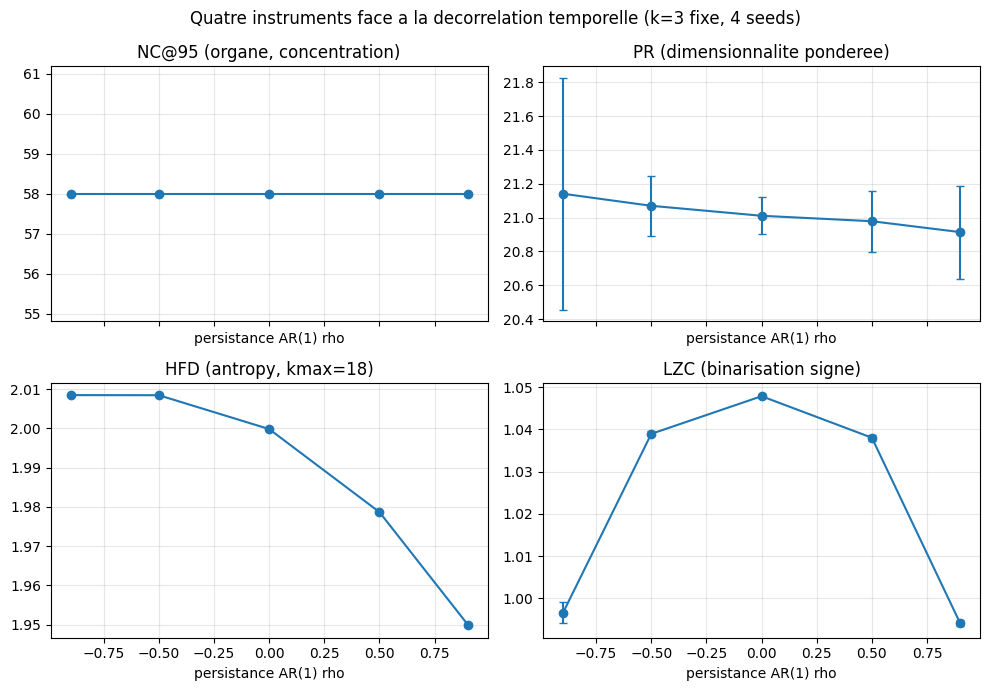

In [5]:
instruments = [("nc95", "NC@95 (organe, concentration)"),
               ("pr", "PR (dimensionnalite ponderee)"),
               ("hfd", "HFD (antropy, kmax=18)"),
               ("lzc", "LZC (binarisation signe)")]

fig, axes = plt.subplots(2, 2, figsize=(10, 7), sharex=True)
for ax, (col, label) in zip(axes.flat, instruments):
    means = [np.mean([r[col] for r in rows if r["rho"] == rho]) for rho in RHO_GRID]
    stds = [np.std([r[col] for r in rows if r["rho"] == rho]) for rho in RHO_GRID]
    ax.errorbar(RHO_GRID, means, yerr=stds, marker="o", capsize=3)
    ax.set_title(label)
    ax.set_xlabel("persistance AR(1) rho")
    ax.grid(alpha=0.3)
fig.suptitle("Quatre instruments face a la decorrelation temporelle (k=3 fixe, 4 seeds)")
fig.tight_layout()
plt.show()

### Lecture du resultat — verdict pre-enregistre

La mesure tranche la question posee en tete, et elle tranche **differemment selon l'instrument** :

- **HFD monte quand rho decroît** (1,95 -> 2,01) : la decorrelation temporelle est visible canal par canal, exactement le sens de l'effet LSD rapporte par Subramani et al. (HFD transmodale en hausse). Sur terrain synthetique a verite exacte, « HFD qui monte » se produit bien **sans aucun changement de la carte des facteurs** — seule l'echelle de temps du signal change.
- **LZC ne suit pas la prediction** : sa courbe est un dôme (0,99 a rho=+0,9, maximum 1,05 a rho=0,0, redescente 1,00 a rho=-0,9) — le contraste entre extremes ne se separe pas. La raison mecanique : un facteur a rho tres negatif oscille de façon quasi periodique pas-a-pas ; binarise au signe, ce motif alternant est *previsible*, donc peu complexe pour LZC. La LZC melange « irregularite » et « desordre », la HFD ne melange que la premiere — sur ce terrain, seule la HFD est un temoin monotone de la decorrelation.
- **NC@95 est invariant au sens exact** : 58,00 +/- 0,00 sur toute la grille — la concentration rendue par l'organe est quantifiee, et sa valeur ne bouge pas d'un cran. La contre-prediction spatiale est confirmee plus nettement encore que prevu.
- **PR ne se separe pas** (+0,4 sigma aux extremes) : legere pente croissante quand rho decroît, coherente avec la variance d'echantillonnage a T = 2048 fini (l'autocorrelation serielle reduit la taille d'echantillon effective), pas avec un effet d'esperance.

Le pont entre les deux litteratures se referme : **le sens d'un mouvement de HFD n'informe pas sur le nombre de facteurs** (ICT-36c : HFD decroît quand k croît) **sans la reference a l'echelle de temps du signal** (ce notebook : HFD croît quand la persistance s'effondre, a k constant). Et la lecon de methode : sur les quatre instruments du pont, **un seul** (la HFD) discrimine monotone cette manipulation — les carrefours inter-domaines ne se traversent pas a instruments multiples sur le meme verdict.

## 5. Discrimination — tailles d'effet (discipline multi-seed)

L'objection « les courbes se touchent presque » se tranche en sigmas inter-seeds : difference des moyennes entre les deux extremes de la grille (rho = +0.9 contre rho = -0.9), normalisee par l'ecart-type liste pooled, seuil 2.

In [6]:
def effect_size(col, rho_a, rho_b):
    """Taille d'effet en sigmas inter-seeds ; None si variance pooled nulle."""
    a = np.array([r[col] for r in rows if r["rho"] == rho_a])
    b = np.array([r[col] for r in rows if r["rho"] == rho_b])
    pooled = np.sqrt((a.std() ** 2 + b.std() ** 2) / 2.0)
    if pooled == 0.0:
        return None
    return float((a.mean() - b.mean()) / pooled)


print("Contraste rho-0.9 vs rho+0.9 (extremes de la grille) :")
for col, label in instruments:
    eff = effect_size(col, -0.9, 0.9)
    if eff is None:
        verdict = "INVARIANT_EXACT (variance inter-seeds nulle aux deux extremes)"
        print(f"{label:<38} effet =    ---        -> {verdict}")
        continue
    sens = "CROISSANT quand rho decroît" if eff > 0 else "DECROISSANT quand rho decroît"
    verdict = f"DETECTE_{sens}" if abs(eff) >= 2 else "NON_SEPARE"
    print(f"{label:<38} effet = {eff:+6.2f} sigma  -> {verdict}")

Contraste rho-0.9 vs rho+0.9 (extremes de la grille) :
NC@95 (organe, concentration)          effet =    ---        -> INVARIANT_EXACT (variance inter-seeds nulle aux deux extremes)
PR (dimensionnalite ponderee)          effet =  +0.43 sigma  -> NON_SEPARE
HFD (antropy, kmax=18)                 effet = +188.12 sigma  -> DETECTE_CROISSANT quand rho decroît
LZC (binarisation signe)               effet =  +1.34 sigma  -> NON_SEPARE


## 6. Exercices

Trois exercices, a completer sans erreur volontaire : chaque stub s'execute tel quel (il affiche ou rend `None`), la correction se fait par edition du corps de fonction.

### Exercice 1 — la limite rho = 1 : marche aleatoire

La grille s'arrete a |rho| = 0.9 car la normalisation `sqrt(1 - rho^2)` degenere a rho = 1 : le facteur devient une marche aleatoire **non stationnaire** (variance croissante), hors du regime stationnaire du terrain. Ecris un generateur de marche aleatoire discrete (pas +/- 1 equiprobables, echelle 1/sqrt(T) pour rester comparable), melange-la aux memes loadings avec le meme bruit, et mesure la HFD du terrain obtenu. Prediction a trancher : la HFD d'une marche aleatoire est-elle au-dessus ou en dessous de celle du facteur rho = +0.9 ?

In [7]:
def hfd_marche_aleatoire(seed):
    """HFD moyenne par canal d'un terrain k=3 ou les facteurs sont des marches aleatoires.

    TODO etudiant
    Indice : pas = rng.choice([-1.0, 1.0], size=(T, k)) ; cumule (np.cumsum) puis
    normalise par sqrt(T) pour un ecart-type d'ordre 1 ; recharge loadings et bruit
    comme build_terrain, puis moyenne des HFD par canal sur les 6 prompts.
    Etape 1 : construire les facteurs marches et les normaliser.
    Etape 2 : assembler resid = signal + noise puis appeler channel_hfd.
    """
    # Exercice a completer
    print("Exercice 1 a completer : HFD du terrain a marches aleatoires vs rho=+0.9")
    return None


hfd_marche_aleatoire(0)


Exercice 1 a completer : HFD du terrain a marches aleatoires vs rho=+0.9


### Exercice 2 — jambe SNR : un facteur faible dans la meme structure

La grille de ce notebook garde le SNR facteur/bruit fixe (~10 dB par facteur). Le terrain suivant ajoute un 4e facteur dont l'amplitude est attenuee a -12 dB sous les autres. Question : a rho = +0.9 fixe, quel est le premier instrument a ne **plus** separer le terrain a 4 facteurs (3 forts + 1 faible) du terrain a 3 facteurs — la HFD temporelle, ou la concentration NC@95 spatiale ? Mesure les deux contrastes en sigmas (4 seeds) et conclus.

In [8]:
def contraste_facteur_faible(seed):
    """Contraste (4-1 faible vs 3 facteurs) pour HFD et NC@95, un seed.

    TODO etudiant
    Indice : terrain_3 = build_terrain(3, seed, 0.9) ; pour le terrain 4-1, construire
    les facteurs par make_factors(., 4, ., 0.9) puis mettre la colonne 3 a l'amplitude
    10**(-12/20) avant l'assemblage loadings @ factors — ou copier build_terrain et
    ajouter l'argument amplitudes. NC@95 se lit via measure_flens(terrain)["per_prompt"].
    Etape 1 : assembler les deux terrains au meme seed.
    Etape 2 : rendre le dict {"hfd": ..., "nc95": ...} des deux niveaux.
    """
    # Exercice a completer
    print("Exercice 2 a completer : contraste HFD vs NC@95 pour un facteur faible")
    return None


contraste_facteur_faible(0)


Exercice 2 a completer : contraste HFD vs NC@95 pour un facteur faible


### Exercice 3 — kmax : la HFD depend-elle du choix de fenetre ?

Le papier selectionne Kmax = 18 par detection de genou. Recalcule la HFD du meme terrain k = 3, rho = -0.9 (seed 0, jeu A, prompt 0) a kmax = 6, 12 et 18 : le contraste rho-0.9 vs rho+0.9 de la section 5 survit-il au choix de kmax ?

In [9]:
def hfd_sensibilite_kmax(seed=0):
    """HFD du terrain k=3 aux deux extremes de rho, pour kmax dans {6, 12, 18}.

    TODO etudiant
    Indice : ent.higuchi_fd(x, kmax=...) ; boucle sur RHO_GRID_EXTREMES = [0.9, -0.9]
    puis sur les trois kmax, et affiche la table (difference incluse).
    Etape 1 : extraire un resid par extreme de rho.
    Etape 2 : boucler sur les kmax et rendre les differences.
    """
    # Exercice a completer
    print("Exercice 3 a completer : HFD a kmax 6/12/18 sur les deux extremes de rho")
    return None


hfd_sensibilite_kmax()


Exercice 3 a completer : HFD a kmax 6/12/18 sur les deux extremes de rho


## 7. Limites et suite

- **Terrain synthetique, verite exacte** : ce notebook etablit la reponse calibree des instruments a la decorrelation temporelle **a structure spatiale constante** — le complement exact d'ICT-36c (structure spatiale variable a dynamique temporelle constante). Ensemble, les deux jambes bornent ce que « HFD monte » peut vouloir dire.
- **Jambe MEG reelle** : conditionnee a l'acces aux donnees MEG-17 de Subramani et al. (non publiques, acces sur demande — verdict etabli dans le grain #20463) ; le repli synthetique reste la reference calibree.
- **Invariance spatiale a T fini** : la contre-prediction NC@95/PR constante vaut en esperance ; l'autocorrelation serielle deplace la variance d'echantillonnage, pas la cible. Un prolongement possible : balayer T pour montrer la convergence des estimateurs spatiaux vers leur limite commune.
- **LZC et binarisation** : la LZC au signe ne partage pas le verdict de la HFD ici — sa reponse est un dome, non monotone en rho ; la sensibilite au seuil de binarisation reste un exercice ouvert (cf. exercice 3 d'ICT-36c), et une binarisation adaptee pourrait-elle la rendre monotone ?